In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.tree import DecisionTreeRegressor,plot_tree
from sklearn.compose import make_column_transformer,make_column_selector
from sklearn.preprocessing import OneHotEncoder
from tqdm import tqdm
import matplotlib.pyplot as plt
import os
os.chdir('E:/Machine_Learning/Datasets/')

In [3]:
housing = pd.read_csv('Housing.csv')
housing.head()

,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,42000.0,5850,3,1,2,yes,no,yes,no,no,1,no
1,38500.0,4000,2,1,1,yes,no,no,no,no,0,no
2,49500.0,3060,3,1,1,yes,no,no,no,no,0,no
3,60500.0,6650,3,1,2,yes,yes,no,no,no,0,no
4,61000.0,6360,2,1,1,yes,no,no,no,no,0,no


In [5]:
X , y = housing.drop('price',axis=1),housing['price']
X_train,X_test,y_train,y_test = train_test_split(X, y ,test_size=0.3,random_state=26)


In [6]:
ohe = OneHotEncoder(sparse_output=False,drop='first')
ct = make_column_transformer(
    (ohe,make_column_selector(dtype_include='object')),
    remainder='passthrough',
    verbose_feature_names_out=False
)
ct = ct.set_output(transform='pandas')


In [10]:
X_trn_ohe , X_tst_ohe = ct.fit_transform(X_train) , ct.transform(X_test)
depths = [None,2,3,4,5,6,7]
min_split = [2,0.05,0.01,0.1,0.2,0.3]
min_leaf = [1,0.05,0.01,0.1,0.2,0.3]
scores = []
for d in tqdm(depths):
    for s in min_split:
        for f in min_leaf:
            dtr = DecisionTreeRegressor(random_state=26,max_depth=d,min_samples_split=s,min_samples_leaf=f)
            dtr.fit(X_trn_ohe,y_train)
            y_pred = dtr.predict(X_tst_ohe)
            scores.append([d,s,f,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Depth','Min_sample_splits','Min_sample_leaf','r2'])
df_scores.sort_values(by='r2',ascending=False)

100%|██████████| 7/7 [00:00<00:00,  7.41it/s]


,Depth,Min_sample_splits,Min_sample_leaf,r2
1,NaN,2.00,0.05,0.526436
7,NaN,0.05,0.05,0.526436
19,NaN,0.10,0.05,0.526436
13,NaN,0.01,0.05,0.526436
193,6.0,0.01,0.05,0.526436
...,...,...,...,...
192,6.0,0.01,1.00,0.358850
228,7.0,0.01,1.00,0.308853
12,NaN,0.01,1.00,0.305639
0,NaN,2.00,1.00,0.286557


In [11]:
X_trn_ohe , X_tst_ohe = ct.fit_transform(X_train) , ct.transform(X_test)
depths = [None,2,3,4,5,6,7]
min_split = [2,5,10,20,50]
min_leaf = [1,5,10,20,50]
scores = []
for d in tqdm(depths):
    for s in min_split:
        for f in min_leaf:
            dtr = DecisionTreeRegressor(random_state=26,max_depth=d,min_samples_split=s,min_samples_leaf=f)
            dtr.fit(X_trn_ohe,y_train)
            y_pred = dtr.predict(X_tst_ohe)
            scores.append([d,s,f,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Depth','Min_sample_splits','Min_sample_leaf','r2'])
df_scores.sort_values(by='r2',ascending=False)

100%|██████████| 7/7 [00:00<00:00,  9.96it/s]


,Depth,Min_sample_splits,Min_sample_leaf,r2
23,NaN,50,20,0.530931
173,7.0,50,20,0.530931
148,6.0,50,20,0.530931
123,5.0,50,20,0.530931
171,7.0,50,5,0.528372
...,...,...,...,...
10,NaN,10,1,0.353734
155,7.0,5,1,0.329882
5,NaN,5,1,0.290221
0,NaN,2,1,0.286557


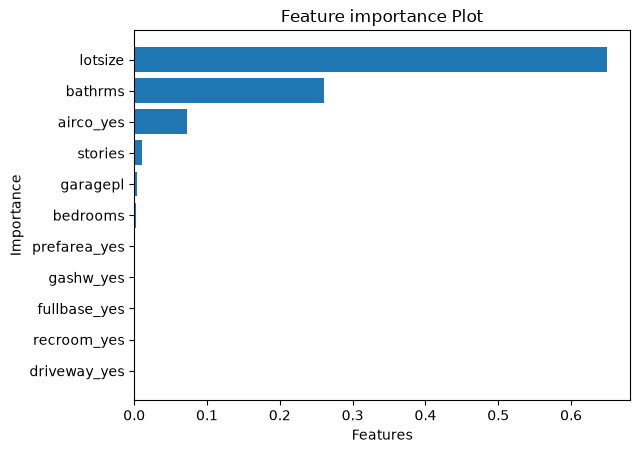

In [17]:
best_tree = DecisionTreeRegressor(random_state=26,min_samples_split=50,min_samples_leaf=20)
best_tree.fit(X_trn_ohe,y_train)
df_imp = pd.DataFrame(
    {'features':list(X_trn_ohe.columns),
    'importance' : best_tree.feature_importances_}
                     )
df_imp.sort_values('importance',inplace=True)
plt.barh(df_imp['features'],df_imp['importance'])
plt.title('Feature importance Plot')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()